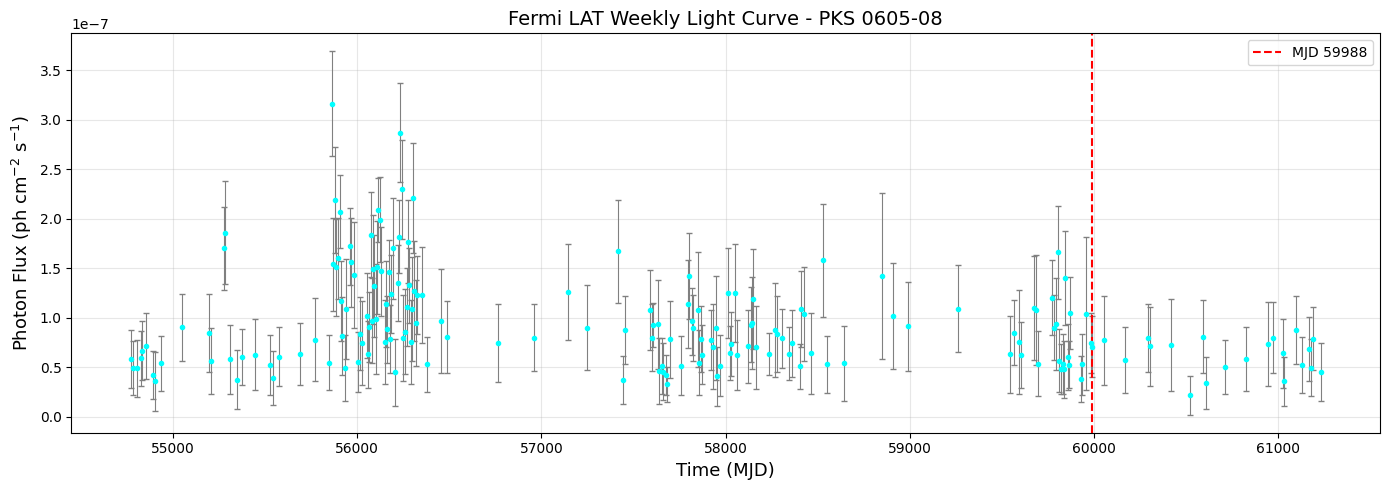

Number of valid flux measurements: 181
MJD range: 54770.5 - 61231.49995370349


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. READ FERMI LAT DATA
# ==========================================

file = "fermiLAT.txt"

# The TXT file is whitespace-separated and has no header
df = pd.read_csv(file, sep=r"\s+", header=None)

# ==========================================
# 2. EXTRACT COLUMNS
# ==========================================

# Column positions based on your TXT file
# 0 = Month
# 1 = Day
# 2 = Year
# 3 = Julian Date
# 4 = MET
# 5 = TS
# 6 = Photon Flux (or "<" for upper limits)
# 7 = Photon Flux Error (or upper-limit value)

# Remove rows containing upper limits
df = df[df[6] != "<"].copy()

# Convert columns to numerical values
df["JD"] = pd.to_numeric(df[3], errors="coerce")
df["Flux"] = pd.to_numeric(df[6], errors="coerce")
df["Flux_Error"] = pd.to_numeric(df[7], errors="coerce")

# ==========================================
# 3. REMOVE INVALID DATA
# ==========================================

df = df.dropna(subset=["JD", "Flux", "Flux_Error"])

# Keep only positive flux values and valid errors
df = df[
    (df["Flux"] > 0) &
    (df["Flux_Error"] > 0)
].copy()

# ==========================================
# 4. CONVERT JD TO MJD
# ==========================================

df["MJD"] = df["JD"] - 2400000.5

# Sort data by time
df = df.sort_values("MJD")

# ==========================================
# 5. PLOT FERMI LAT LIGHT CURVE
# ==========================================

plt.figure(figsize=(14, 5))

plt.errorbar(
    df["MJD"],
    df["Flux"],
    yerr=df["Flux_Error"],
    fmt="o",
    color="cyan",
    ecolor="gray",
    markersize=3,
    elinewidth=0.8,
    capsize=2,
    linestyle="none"
)

plt.xlabel("Time (MJD)", fontsize=13)
plt.ylabel(
    r"Photon Flux (ph cm$^{-2}$ s$^{-1}$)",
    fontsize=13
)

plt.title(
    "Fermi LAT Weekly Light Curve - PKS 0605-08",
    fontsize=14
)
plt.axvline(
    x=59988,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="MJD 59988"
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 6. PRINT DATA INFORMATION
# ==========================================

print("Number of valid flux measurements:", len(df))
print("MJD range:", df["MJD"].min(), "-", df["MJD"].max())